In [1]:
import matplotlib.pyplot as plt
%matplotlib inline

import torch
import torch.nn.functional as F

This notebook highlights the importance of gradients and activations and their statistics. 

In [2]:
# read in words 
words = open("data/names.txt", "r").read().splitlines()

In [3]:
# Construct mappings between characters and indicies
chars = sorted(list(set("".join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)} # string-to-index
stoi["."] = 0
itos = {i:s for s, i in stoi.items()} # index-to-string

In [4]:
# Build the dataset, with splitting of input sets
blocksize = 3

# Set the context length 
def build_dataset(words, blocksize=blocksize):
    blocksize = blocksize
    X, Y = [], []

    for w in words:
        context = [0] * blocksize
        for ch in w + ".":
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print("".join(itos[i] for i in context), "--->", itos[ix])
            context = context[1:] + [ix] 

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

# shuffle up the input data, and split up the data
import random
random.seed(67)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1], blocksize=blocksize)
Xdev, Ydev = build_dataset(words[n1:n2], blocksize=blocksize)
Xtest, Ytest = build_dataset(words[n2:], blocksize=blocksize)

In [5]:
# Expected loss for all letters equally likely
-torch.tensor(1/27).log()

tensor(3.2958)

### Initialization
It's important to initialize with reasonable guesses. Starting the NN parameters with random numbers can result in very bad guesses, leading to a very high loss. The initial loss will be capped near a lower value ($-\log(1/27)=3.3$) if the outputs are initialized with near zeros.

Note that biases can be set to exactly zero, but weights should not be exactly zero. Output weights should be near zero, so that the gradient will still impact parameter updates. 

Importantly, deeper networks become more sensitive to bad initializations, so its importent to be careful and to consider the ways training can run afoul. 

In [43]:
n_embed = 10
n_hidden = 200
batch_size = 32

# Initialize the NN params
g = torch.Generator().manual_seed(67)
C = torch.randn((batch_size, n_embed), generator=g) # 10 D n_embed
# Scale by the kaiming init for tanh nonlinearity
W1 = torch.randn((n_embed * blocksize, n_hidden), generator=g) * (5/3) / (n_embed * blocksize)**0.5
# b1 = torch.randn(n_hidden, generator=g) * 0.01
W2 = torch.randn((n_hidden, batch_size), generator=g) * 0.01
b2 = torch.randn(batch_size, generator=g) * 0

# Parameters, etc. related to batch normalization
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
for p in parameters:
    p.requires_grad = True

But, how are these constants for minimizing initial weights set? 

tensor(0.0176) tensor(1.0088)
tensor(0.0028) tensor(3.1569)


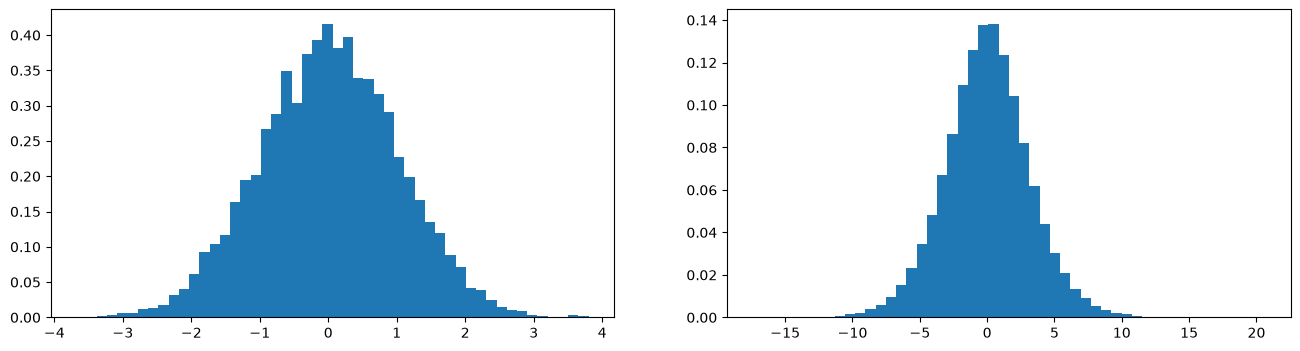

In [27]:
x = torch.randn(1000, 10)
w = torch.randn(10, 200) #/ 10**0.5
y = x @ w
print(x.mean(), x.std())
print(y.mean(), y.std())
plt.figure(figsize=(16,4))
plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50, density=True);
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density=True);

Notice the large increase in the standard deviation after activation. This is undesirable. So the idea is to scale w, so that the standard deviation is roughly similar after activation. The heuristic is, divide the matrix by th square root of the number of inputs. So in this case above, $$y = x @ (w / \sqrt{10})$$

In fact, torch has a commonly used function for initializing weights in this way : `torch.nn.init.kaiming_normal_()` (Kaiming He et al. authored the paper which analyzes the weight initializations forward and back propogation behavior )

### Batch normalization
More important than proper initialization is batch normalization (2015).  
Preactivation inputs to $\tanh()$ need to be roughly a normalized gaussian, 0 mean and std 1. So just normalize them to be gaussian. 
We normalize the batches before passing them into the activation function, so they are unit gaussian during intialization. Then, a gain and bias is applied to the gaussian to allow training to shift and squeeze and otherwise alter the input pre-activation gaussian. 

The "problem" with batch normalization is that the examples in the batches are coupled to one another; they are no longer computed independently. This creates variability in the preactivation value and in $h$. This variability is actually helpful for training because it results in an added stochastic effect which reduces overfitting.

Additionally, the bias `b1` does nothing in batch normalization, so may as well remove it. The batch normalization bias `bnbias` takes care of the bias addition. 

During normalization, it can also be a good idea to add a small number $\epsilon$ in the denominator to ensure values are well behaved and there is no division by zero.

**NB**: Batch Normalization can be highly error prone due to coupling of examples in forward passes. So, in practice, other kinds of normalization layers like group normalization or layer normalization are used more commonly.

In [44]:
# Train the NN
runs = 200000
loses = []
stepi = []

In [45]:
for k in range(runs):

    # Construct minibatch
    batch = torch.randint(0, Xtr.shape[0], (batch_size,))
    Xb, Yb = Xtr[batch], Ytr[batch]

    # Forward pass
    emb = C[Xb]
    embcat = emb.view(emb.shape[0], -1)
    # Linear layer
    hpreact = embcat @ W1 # + b1
    # BatchNorm layer
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True) 
    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
    # Nonlinear activation
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    # Compute loss
    loss = F.cross_entropy(logits, Yb)

    # Back pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # Update weights
    lr = 0.1 if k < 100000 else 0.1
    for p in parameters:
        p.data += -lr * p.grad 

    # Track stats
    if k % 10000 == 0:
        print(f"step { k } :    | loss : { loss }")

    loses.append(loss.item())
    stepi.append(k)

    # break

print(loses[-1])

step 0 :    | loss : 3.5043845176696777
step 10000 :    | loss : 2.3810715675354004
step 20000 :    | loss : 2.390943765640259
step 30000 :    | loss : 2.4062764644622803
step 40000 :    | loss : 2.0236876010894775
step 50000 :    | loss : 2.195356845855713
step 60000 :    | loss : 2.143798589706421
step 70000 :    | loss : 2.1319453716278076
step 80000 :    | loss : 2.2119693756103516
step 90000 :    | loss : 2.0590436458587646
step 100000 :    | loss : 2.0293381214141846
step 110000 :    | loss : 2.216369390487671
step 120000 :    | loss : 2.1821775436401367
step 130000 :    | loss : 2.002419948577881
step 140000 :    | loss : 1.9430464506149292
step 150000 :    | loss : 1.7306005954742432
step 160000 :    | loss : 1.845157504081726
step 170000 :    | loss : 2.200774669647217
step 180000 :    | loss : 2.4354166984558105
step 190000 :    | loss : 2.0656230449676514
2.373573064804077


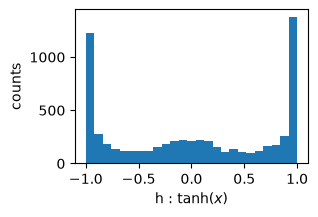

In [21]:
# What happens with h?
fig, ax = plt.subplots(figsize=(3,2))
ax.hist(h.view(-1).tolist(), 25)
ax.set_xlabel(r"h : $\tanh(x)$")
ax.set_ylabel("counts")
# fig.savefig("figures/tanh_before_smart_initialization.png")
fig.savefig("figures/tanh_after_smart_initialization.png")

Almost all the $h$ values are essentially 1, or -1. This is big problem because on back propagation, it becomes very difficult to change parameter. The gradient update is `self.grad += (1 - h**2) * out.grad`, which kills changes to the gradient change, since we multiply by nearly zero.

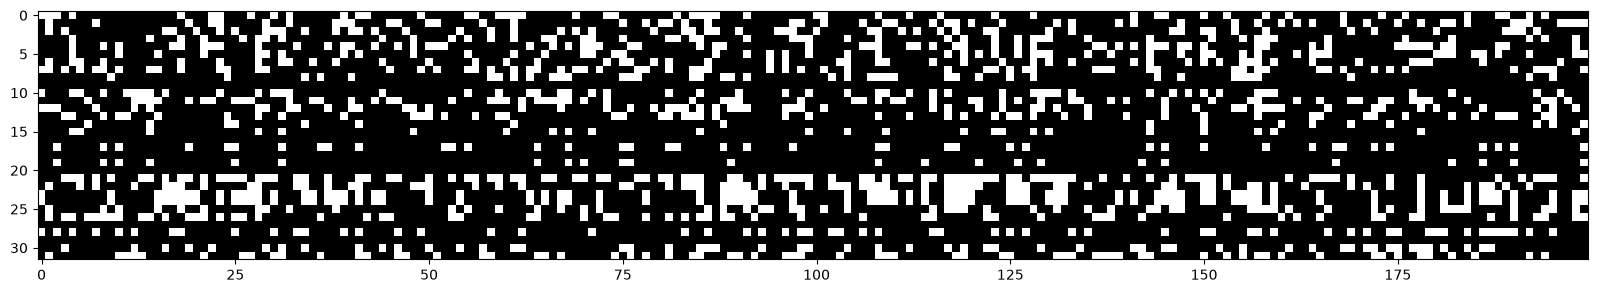

In [22]:
# Check for dead neurons
plt.figure(figsize=(20,5))
plt.imshow(h[:32].abs() > 0.99, cmap="gray", interpolation="nearest")
fig.savefig("figures/batch_tanh_after_smart_initialization.png")

Some neurons are nearly dead, but there aren't any totally white columns. The problem is that the pre-activation values (before $\tanh$) are just too large. 

At the end of training, we need to calibrate the batch norm. This allows us to use the trained network to make individual predictions, although it was trained on batches.
This does not need to be computed after the fact; it can be comptuted during training, which has been incorporated above.

In [38]:
# Pass the full training set through
with torch.no_grad():
    emb = C[Xtr]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 + b1
    # Comput the mean / std over the full training set
    bnmean = hpreact.mean(0, keepdim=True)
    bnstd = hpreact.std(0, keepdim=True)

In [46]:
# Just use the BN mean / std that were computed at runtime
bnmean = bnmean_running
bnstd = bnstd_running

In [47]:
# Evaluate loss
def split_loss(split):
    x,y = {
        "train" : (Xtr, Ytr),
        "val" : (Xdev, Ydev),
        "test" : (Xtest, Ytest)
    }[split]
    emb = C[x]
    embcat = emb.view(emb.shape[0], -1) 
    hpreact = embcat @ W1 + b1
    hpreact = bngain * (hpreact - bnmean) / bnstd + bnbias
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, y)
    return loss

print(f"Training loss : { split_loss("train") }")
print(f"Validation loss : { split_loss("val") }")

Training loss : 2.1186797618865967
Validation loss : 2.1465179920196533


In [48]:
# Sample form the model
g = torch.Generator().manual_seed(67)

for _ in range(15):
    out = []
    context = [0] * blocksize
    while True:
        emb = C[torch.tensor([context])]
        embcat = emb.view(emb.shape[0], -1) 

        hpreact = embcat @ W1 + b1
        hpreact = bngain * (hpreact - bnmean) / bnstd + bnbias
        h = torch.tanh(hpreact)

        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break

    print("".join(itos[i] for i in out))

jolemira.
mika.
daralien.
jamayferthamumreen.
amartermyna.
bena.
jeston.
harnaj.
astamu.
allia.
thoys.
kani.
kaleig.
akazim.
aarick.
